036 - K-Vecinos más cercanos (KNN)
---

* K-Nearest Neighbors (KNN)
* Algoritmos de aprendizaje automático
* Realiza predicciones observando a los k vecinos más cercanos en el espacio de características y asignando un valor (clasificación o regresión) basado en sus características
* KNN es un algoritmo de aprendizaje perezoso que no aprende una función explícita durante el entrenamiento. En su lugar, almacena todo el conjunto de datos y realiza predicciones en tiempo de ejecución calculando la similitud (o distancia) entre los puntos de datos

## Pasos en KNN

1. Elegir el valor de k (número de vecinos)
2. Calcular la distancia entre el punto de consulta y todos los puntos de datos del conjunto de datos (por ejemplo, distancia euclidiana)
3. Seleccionar los k vecinos más cercanos
4. Vota por la etiqueta de clase (clasificación) o toma el promedio (regresión)

## Conceptos en KNN

* **Métricas de distancia**: euclidiana, manhattan, minkowski
* **Elección de k**: pequeños pueden provocar sobreajuste (demasiado sensible al rudio), grandes pueden provocar un subajuste (sobresuavizado)
* **Votación ponderada**: asignar pesos más altos a los vecinos más cercanos para mejorar la precisión

## Ventajas y Desventajas

* Ventajas:
    * Sencillo e intuitivo
    * Funciona bien para conjuntos de datos pequeños
    * No es necesario ningún entrenamiento explícito
* Desventajas:
    * Computacionalmente costoso para grandes conjuntos de datos
    * Sensible a características ruidosas e irrelevantes
    * Requiere mucha memoria, ya que almacena todo el conjunto de datos

## Casos de uso reales

* **Segmentación de clientes**: agrupación de clientes en función de su comportamiento de compra
* **Sistemas de recomendación**: sugieren productos en función de la similitud de los usuarios
* **Detección de fraude**: identificación de patrones inusuales en transacciones financieras
* **Diagnóstico médico**: clasificación de enfermedades según los síntomas

## Ejemplo KNN para predicción de enfermedades cardíacas

### Paso 1: Cargar y explorar los datos

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
data = pd.read_csv('data/heart.csv')
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
# Overview of dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [4]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [5]:
# Check for missing values
data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

### Paso 2: Análisis exploratorio de datos

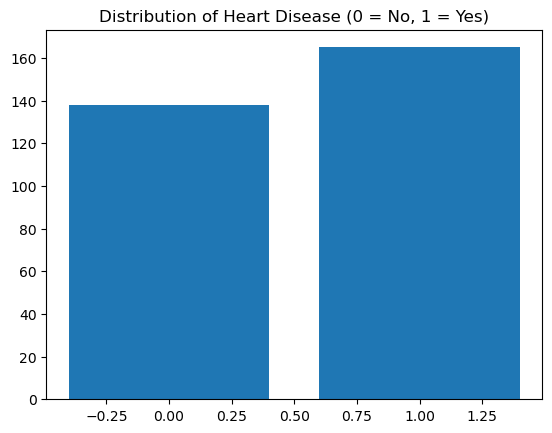

In [7]:
# Univariate Analysis
# Count the occurrences of 0 and 1 in the 'target' column
count_data = data['target'].value_counts()

# Distribution of target variable
plt.bar(count_data.index, count_data.values)
plt.title('Distribution of Heart Disease (0 = No, 1 = Yes)')
plt.show()

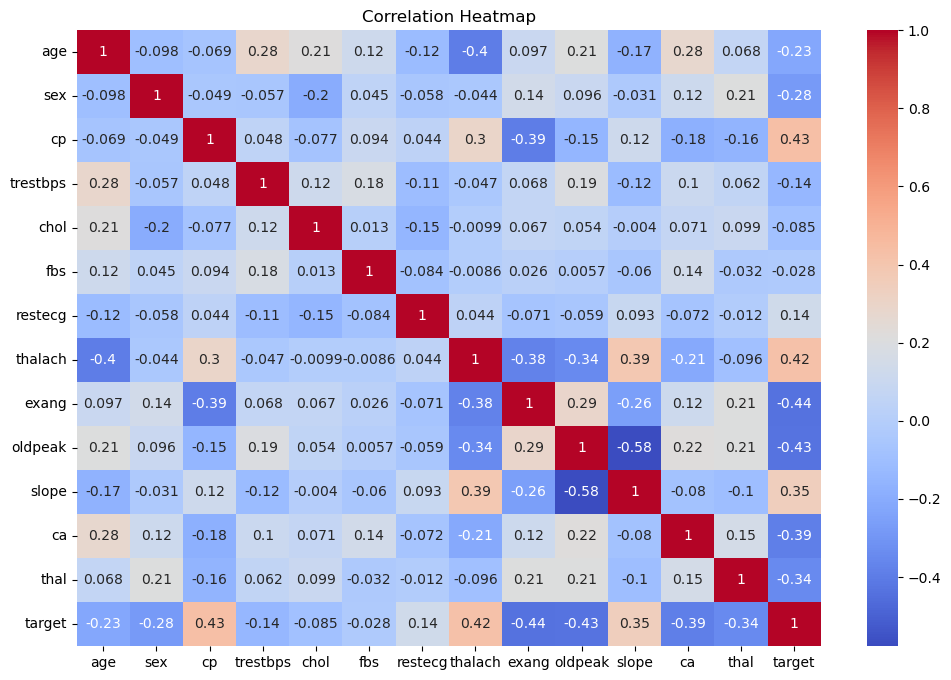

In [8]:
# Bivariate Analysis
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

* El mapa de calor muestra la correlación entre las variables. Las variables con alta correlación pueden agregar redundancia, lo que requiere la reducción de la dimensionalidad o la selección de características
* Por ejemplo, si dos características están altamente correlacionadas (por ejemplo, chol y age), se podría eliminar una para simplificar el modelo

### Paso 3: Preprocesamiento

In [15]:
from sklearn.preprocessing import StandardScaler

# Normalize Numerical Features
scaler = StandardScaler()
numerical_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
data[numerical_features] = scaler.fit_transform(data[numerical_features])

# Encode Categorical Variables
#data = pd.get_dummies(data, columns=['sex', 'cp', 'restecg', 'slope', 'ca', 'thal'], drop_first=True)

# Handle Class Imbalance
from imblearn.over_sampling import SMOTE

X = data.drop('target', axis=1)
y = data['target']

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

### Paso 4: División de entrenamiento y prueba

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)


### Paso 5: Construir y evaluar el modelo KNN

In [22]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Train KNN model
# El modelo considera cinco vecinos más cercanos para la predicción
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Predictions
y_pred = knn.predict(X_test)

# Confusion matrix
print(confusion_matrix(y_test, y_pred))

# Classification report
print(classification_report(y_test, y_pred))

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))                     

[[24  8]
 [ 3 31]]
              precision    recall  f1-score   support

           0       0.89      0.75      0.81        32
           1       0.79      0.91      0.85        34

    accuracy                           0.83        66
   macro avg       0.84      0.83      0.83        66
weighted avg       0.84      0.83      0.83        66

Accuracy: 0.8333333333333334


### Paso 6: Ajuste de hiperparámetros

In [23]:
from sklearn.model_selection import GridSearchCV

# Grid search for best k
param_grid = {'n_neighbors': np.arange(1, 31)}

# La validación cruzada (cv) garantiza un rendimiento sólido en todas las divisiones de datos
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Best k value
print("Best k:", grid_search.best_params_['n_neighbors'])

Best k: 1


### Paso 7: Visualización de resultados

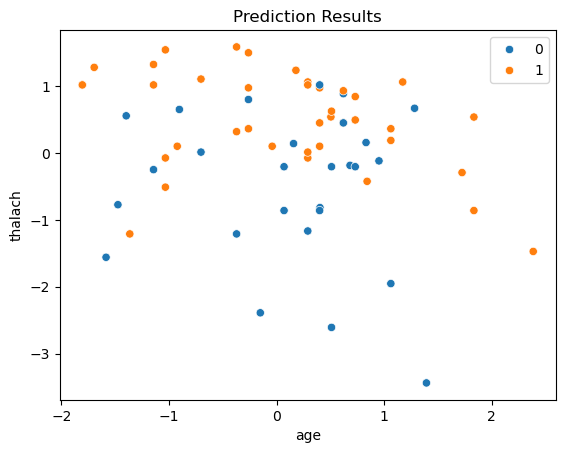

In [24]:
# Visualize predictions
sns.scatterplot(x=X_test['age'], y=X_test['thalach'], hue=y_pred)
plt.title('Prediction Results')
plt.show()

El diagrama de dispersión muestra grupos de predicciones y revela patrones sobre cómo la edad y la frecuencia cardíaca se correlacionan con la enfermedad cardíaca